# 02 Funnel Validation

**Question:** Do bids, impressions, clicks and conversions add up?

This notebook builds on the database from Notebook 01 (`data/processed/ipinyou.duckdb`, with its `typed_imp`, `typed_clk`, `typed_conv` and `typed_bid` views). It answers four things:

1. **How to link events to impressions.** `bid_id` alone is not enough: Notebook 01 found 45,044 impression bid IDs that repeat with a *different user and timestamp*.
2. **Does the funnel nest?** Every click needs an impression, every impression needs a bid, and conversions can't outnumber clicks.
3. **Do the totals match the dataset paper** (Zhang et al., 2014, Table 3)?
4. **Which date does a click or conversion belong to?** The impression date or the event date. This notebook records the decision.

It ends with the funnel KPI table (all rates are ratios of sums) and the Findings.


### Setup

In [1]:
# CELL 1: setup (read-only connection: this notebook writes nothing to disk)
from pathlib import Path
import os, re, shutil, signal, time
import duckdb
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

# Set to True ONLY if this cell reports that another Python process holds the database lock
# and you are sure that process is an old or stray notebook (its unsaved variables will be lost).
KILL_STALE = False
RUN_BID_LINK_CHECK = True   # impressions -> bids check: reads all 53M bids, a few minutes. Set False to skip.

PROJECT_ROOT = Path.cwd().parent
# Where the data comes from (the views raw_* and typed_* are the same either way):
#   1. data/processed/ipinyou.duckdb, the database the loading notebook built, if it is still there
#   2. otherwise the pipeline's hourly Parquet files in data/interim, read in memory (pipeline_views.py)
DB_PATH = PROJECT_ROOT / "data" / "processed" / "ipinyou.duckdb"
BID_DIR = PROJECT_ROOT / "data" / "interim" / "bid_parquet"
ADVERTISERS = [1458, 3358, 3386, 3427, 3476]

free_gb = shutil.disk_usage(PROJECT_ROOT).free / 1e9
print(f"Free disk space: {free_gb:.1f} GB", "(fine: this notebook is read-only)" if free_gb < 1 else "")

if "con" in globals():
    try:
        con.close()
    except Exception:
        pass

def open_db(path, kill_stale=False, retries=5):
    """Read-only connection. If another process holds the lock, explain it (and optionally stop it)."""
    for attempt in range(retries):
        try:
            return duckdb.connect(str(path), read_only=True)
        except duckdb.IOException as e:
            msg = str(e)
            m = re.search(r"PID (\d+)", msg)
            if "lock" not in msg.lower() or m is None:
                raise
            pid = int(m.group(1))
            print(f"The database is locked by another Python process (PID {pid}).")
            if not kill_stale:
                print("Shut down the other notebook (Jupyter > Running tab > Shut Down), "
                      "or set KILL_STALE = True and run this cell again.")
                raise
            print(f"KILL_STALE is True: stopping PID {pid} ...")
            os.kill(pid, signal.SIGTERM)
            time.sleep(2)
    raise RuntimeError("Could not get the database lock after several tries")

if DB_PATH.exists():
    con = open_db(DB_PATH, kill_stale=KILL_STALE)
    DATA_SOURCE = f"{DB_PATH.name} (the loading notebook's database)"
else:
    from pipeline_views import create_views
    con = duckdb.connect()   # in memory: reads the Parquet files, writes nothing to disk
    DATA_SOURCE = create_views(con, PROJECT_ROOT)
con.execute("SET preserve_insertion_order=false")
try:
    con.execute("SET enable_progress_bar=false")   # quieter output
except Exception:
    pass

def q(sql):
    return con.execute(sql).df()

# The views from Notebook 01 must exist. typed_bid is rebuilt in memory if it's missing.
views = set(q("SELECT view_name FROM duckdb_views() WHERE NOT internal")["view_name"])
missing = {"typed_imp", "typed_clk", "typed_conv"} - views
assert not missing, f"Run Notebook 01 first: missing views {missing}"
if "typed_bid" not in views:
    files = [str(p) for p in sorted(BID_DIR.glob("bid_*.parquet"))]
    files += [str(p) for p in sorted(BID_DIR.glob("bid_*/part_*.parquet")) if not p.parent.name.endswith(".partial")]
    con.execute("CREATE TEMP VIEW typed_bid AS SELECT bid_id, TRY_CAST(advertiser_id AS BIGINT) AS advertiser_id, "
                "regexp_extract(filename, '([0-9]+)\\.txt$', 1) AS log_date FROM read_parquet(["
                + ", ".join(f"'{x}'" for x in files) + "])")
    print("typed_bid rebuilt as a temporary view over", len(files), "Parquet files")
print("Data:", DATA_SOURCE)

# Wilson 95% interval for a proportion (better than p ± 1.96·se when p is tiny, like a CTR)
def wilson(k, n, z=1.959964):
    k, n = np.asarray(k, float), np.asarray(n, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        d = 1 + z**2 / n
        c = (p + z**2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return np.where(n > 0, c - h, np.nan), np.where(n > 0, c + h, np.nan)

# Dataset paper, Table 3 (Season 2 training set). Cost = sum(paying price) / 1000.
PAPER = pd.DataFrame(
    [(1458, 14_701_496, 3_083_056, 2_454, 1, 212_400), (3358, 3_751_016, 1_742_104, 1_358, 369, 160_943),
     (3386, 14_091_931, 2_847_802, 2_076, 0, 219_066), (3427, 14_032_619, 2_593_765, 1_926, 0, 210_239),
     (3476, 6_712_268, 1_970_360, 1_027, 26, 156_088)],
    columns=["advertiser_id", "bids", "imps", "clicks", "convs", "cost"])

Free disk space: 2.5 GB 
Data: ipinyou.duckdb (the loading notebook's database)


### Step 1: link every click and conversion to its impression

Notebook 01 showed that one `bid_id` can belong to **several impressions**: the same ID with a different user and timestamp. Joining on `bid_id` alone would attach a click to every one of them and inflate the clicked impressions.

The rule, tried in order:

| Tier | Match | Meaning |
|---|---|---|
| 1 | same `bid_id` **and** same user, the latest impression **at or before** the event | the normal case |
| 2 | same `bid_id`, any user, latest impression at or before the event | user ID changed (cookie reset) |
| 3 | same `bid_id`, nearest impression in time, even if *after* the event | clock skew between logs |
| 4 | no impression with this `bid_id` | orphan event: excluded from the KPIs |

"The latest impression at or before" is exactly what DuckDB's **ASOF JOIN** does. Exact duplicate rows (identical in every column) are dropped first.

An **impression** is identified by `bid_id + user + timestamp` (`imp_key`). In Notebook 01, those three together made 91,778 of the 91,784 repeated rows unique; the remaining 6 are exact duplicates.

In [2]:
# CELL 2: linking (all TEMP tables, in memory and small: only impressions whose bid_id was clicked or converted)
con.execute("""
CREATE OR REPLACE TEMP TABLE imp_c AS
SELECT DISTINCT bid_id, ipinyou_id, timestamp AS imp_ts, log_date AS imp_date, advertiser_id, paying_price,
       hash(bid_id, ipinyou_id, timestamp) AS imp_key
FROM typed_imp
WHERE bid_id IN (SELECT bid_id FROM typed_clk UNION SELECT bid_id FROM typed_conv)
""")

def link_events(log):
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE {log}_m AS
    WITH e AS (
        SELECT row_number() OVER () AS ev_id, bid_id, ipinyou_id, timestamp AS ev_ts, log_date AS ev_date,
               advertiser_id
        FROM (SELECT DISTINCT * FROM typed_{log})),                       -- exact duplicates dropped
    m1 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i
           ON e.bid_id = i.bid_id AND e.ipinyou_id = i.ipinyou_id AND e.ev_ts >= i.imp_ts),
    m2 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i
           ON e.bid_id = i.bid_id AND e.ev_ts >= i.imp_ts),
    m3 AS (SELECT e.ev_id, arg_min(i.imp_key, abs(epoch(e.ev_ts) - epoch(i.imp_ts))) AS imp_key
           FROM e JOIN imp_c i USING (bid_id) GROUP BY 1)
    SELECT e.*,
           coalesce(m1.imp_key, m2.imp_key, m3.imp_key) AS imp_key,
           CASE WHEN m1.imp_key IS NOT NULL THEN 1 WHEN m2.imp_key IS NOT NULL THEN 2
                WHEN m3.imp_key IS NOT NULL THEN 3 ELSE 4 END AS tier
    FROM e LEFT JOIN m1 USING (ev_id) LEFT JOIN m2 USING (ev_id) LEFT JOIN m3 USING (ev_id)
    """)
    # bring in the impression's details
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE {log}_m AS
    SELECT m.*, i.imp_ts, i.imp_date, i.advertiser_id AS imp_advertiser_id, i.paying_price
    FROM {log}_m m LEFT JOIN imp_c i USING (imp_key)
    """)

link_events("clk")
link_events("conv")

# Conversions: was the impression clicked (post-click) or only seen (post-view)?
con.execute("""
CREATE OR REPLACE TEMP TABLE conv_m AS
SELECT v.*, c.first_click_ts,
       CASE WHEN v.imp_key IS NULL THEN 'no impression'
            WHEN c.first_click_ts IS NULL THEN 'post-view (no click)'
            ELSE 'post-click' END AS conv_type
FROM conv_m v
LEFT JOIN (SELECT imp_key, min(ev_ts) AS first_click_ts FROM clk_m WHERE imp_key IS NOT NULL GROUP BY 1) c
USING (imp_key)
""")

tier_names = {1: "1 same bid_id + user, after impression", 2: "2 same bid_id, other user",
              3: "3 same bid_id, event before impression", 4: "4 no impression (orphan)"}
link = q("""
    SELECT 'clk' AS log, tier, count(*) AS events FROM clk_m GROUP BY ALL
    UNION ALL SELECT 'conv', tier, count(*) FROM conv_m GROUP BY ALL ORDER BY 1, 2""")
link["tier"] = link["tier"].map(tier_names)
link["share"] = link.events / link.groupby("log").events.transform("sum")
display(link)

# How much would bid_id-only linking have inflated clicked impressions?
naive = q("""SELECT count(*) AS impression_rows_hit FROM typed_imp
             WHERE bid_id IN (SELECT DISTINCT bid_id FROM typed_clk)""").iloc[0, 0]
proper = q("SELECT count(DISTINCT imp_key) FROM clk_m WHERE imp_key IS NOT NULL").iloc[0, 0]
print(f"Clicked impressions: {proper:,} with this rule vs {naive:,} impression rows hit by joining on bid_id alone "
      f"(+{naive - proper:,}, {naive / proper - 1:+.1%})")

,log,tier,events,share
0,clk,"1 same bid_id + user, after impression",8047,0.806474
1,clk,"2 same bid_id, other user",1172,0.117458
2,clk,"3 same bid_id, event before impression",655,0.065644
3,clk,4 no impression (orphan),104,0.010423
4,conv,"1 same bid_id + user, after impression",299,0.715311
5,conv,"2 same bid_id, other user",106,0.253589
6,conv,4 no impression (orphan),13,0.031100


Clicked impressions: 8,751 with this rule vs 8,841 impression rows hit by joining on bid_id alone (+90, +1.0%)


### Step 2: repeated events (the counting rule)

After exact duplicates are removed, the rule for each log is:
* **Impressions:** one per `imp_key` (bid_id + user + timestamp).
* **Clicks:** a user can click the same ad more than once. Those repeat clicks are real events, so they are kept as **click events**. CTR counts **clicked impressions** (0/1 per impression), so it stays a true proportion: you can't have more clicks than impressions, and confidence intervals stay valid.
* **Conversions:** counted as **converted impressions** (0/1). Raw rows are kept only for comparison with the paper.

In [3]:
# CELL 3: how many clicks per clicked impression? how far apart?
display(q("""
    WITH per_imp AS (SELECT imp_key, count(*) AS clicks, epoch(max(ev_ts)) - epoch(min(ev_ts)) AS span_s
                     FROM clk_m WHERE imp_key IS NOT NULL GROUP BY 1)
    SELECT clicks AS clicks_on_one_impression, count(*) AS impressions,
           round(median(span_s), 1) AS median_seconds_first_to_last
    FROM per_imp GROUP BY 1 ORDER BY 1"""))

display(q("""
    SELECT 'clk' AS log, (SELECT count(*) FROM typed_clk) AS raw_rows, count(*) AS after_exact_dedup,
           count(*) FILTER (WHERE imp_key IS NOT NULL) AS linked_events,
           count(DISTINCT imp_key) AS distinct_impressions FROM clk_m
    UNION ALL
    SELECT 'conv', (SELECT count(*) FROM typed_conv), count(*), count(*) FILTER (WHERE imp_key IS NOT NULL),
           count(DISTINCT imp_key) FROM conv_m"""))

,clicks_on_one_impression,impressions,median_seconds_first_to_last
0,1,8039,0.0
1,2,513,5.2
2,3,115,16.5
3,4,39,22.0
4,5,21,28.9
5,6,8,36.3
6,7,6,35.3
7,8,2,60.7
8,9,1,49.7
9,10,1,83.1


,log,raw_rows,after_exact_dedup,linked_events,distinct_impressions
0,conv,494,418,405,391
1,clk,9978,9978,9874,8751


### Step 3: does the funnel nest?

The checks:
* bids ≥ impressions ≥ clicked impressions ≥ converted (post-click) impressions, for every campaign and day
* every impression has a bid (`RUN_BID_LINK_CHECK`)
* every click comes after its impression, and every conversion after its click

The impression → bid check runs day by day. It compares 64-bit hashes of `bid_id`, and allows the bid to be logged the day before (just before midnight). That keeps memory low on 53 million bids.

In [4]:
# CELL 4: counts per advertiser and day, and the nesting checks
imps_ad = q("""SELECT advertiser_id, imp_date AS date, count(*) AS imp_rows,
                      count(DISTINCT hash(bid_id, ipinyou_id, timestamp)) AS imps
               FROM (SELECT *, log_date AS imp_date FROM typed_imp) GROUP BY ALL""")
bids_ad = q("SELECT advertiser_id, log_date AS date, count(*) AS bids FROM typed_bid GROUP BY ALL")
clk_ad = q("""SELECT imp_advertiser_id AS advertiser_id, imp_date AS date,
                     count(DISTINCT imp_key) AS clicked_imps, count(*) AS click_events
              FROM clk_m WHERE imp_key IS NOT NULL GROUP BY ALL""")
conv_ad = q("""SELECT imp_advertiser_id AS advertiser_id, imp_date AS date,
                      count(DISTINCT imp_key) FILTER (WHERE conv_type = 'post-click') AS postclick_conv_imps,
                      count(DISTINCT imp_key) FILTER (WHERE conv_type = 'post-view (no click)') AS postview_conv_imps
               FROM conv_m WHERE imp_key IS NOT NULL GROUP BY ALL""")
daily = (bids_ad.merge(imps_ad, on=["advertiser_id", "date"], how="outer")
         .merge(clk_ad, on=["advertiser_id", "date"], how="outer")
         .merge(conv_ad, on=["advertiser_id", "date"], how="outer").fillna(0)
         .sort_values(["advertiser_id", "date"]).reset_index(drop=True))
for c in daily.columns.drop(["date"]):
    daily[c] = daily[c].astype("int64")

# "Conversions never exceed clicks", checked three ways, per campaign-day AND per campaign
raw_cd = q("""SELECT advertiser_id, log_date AS date, count(*) AS click_rows, 0 AS conv_rows FROM typed_clk GROUP BY ALL
              UNION ALL
              SELECT advertiser_id, log_date, 0, count(*) FROM typed_conv GROUP BY ALL""") \
         .groupby(["advertiser_id", "date"], as_index=False)[["click_rows", "conv_rows"]].sum()
all_conv = daily.postclick_conv_imps + daily.postview_conv_imps
per_camp = daily.groupby("advertiser_id")[["clicked_imps", "postclick_conv_imps", "postview_conv_imps"]].sum()
raw_camp = raw_cd.groupby("advertiser_id")[["click_rows", "conv_rows"]].sum()
checks = [
    ("bids >= impressions (campaign-days)", int((daily.imps > daily.bids).sum())),
    ("impressions >= clicked impressions (campaign-days)", int((daily.clicked_imps > daily.imps).sum())),
    ("clicked >= post-click converted impressions (campaign-days)", int((daily.postclick_conv_imps > daily.clicked_imps).sum())),
    ("clicked >= ALL converted impressions, incl. post-view (campaign-days)", int((all_conv > daily.clicked_imps).sum())),
    ("click rows >= conversion rows, raw logs (campaign-days)", int((raw_cd.conv_rows > raw_cd.click_rows).sum())),
    ("clicked >= ALL converted impressions (campaign totals)",
     int(((per_camp.postclick_conv_imps + per_camp.postview_conv_imps) > per_camp.clicked_imps).sum())),
    ("click rows >= conversion rows, raw logs (campaign totals)", int((raw_camp.conv_rows > raw_camp.click_rows).sum())),
]
order = q("""
    SELECT count(*) FILTER (WHERE tier IN (1, 2)) AS clicks_after_impression,
           count(*) FILTER (WHERE tier = 3)       AS clicks_before_impression,
           count(*) FILTER (WHERE tier = 4)       AS clicks_without_impression
    FROM clk_m""").iloc[0]
vorder = q("""
    SELECT count(*) FILTER (WHERE conv_type = 'post-click' AND ev_ts < first_click_ts) AS conv_before_click,
           count(*) FILTER (WHERE tier = 4) AS conv_without_impression
    FROM conv_m""").iloc[0]
checks += [("clicks before their impression (clock skew)", int(order.clicks_before_impression)),
           ("clicks without any impression", int(order.clicks_without_impression)),
           ("conversions before their click", int(vorder.conv_before_click)),
           ("conversions without any impression", int(vorder.conv_without_impression))]

if RUN_BID_LINK_CHECK:
    days = sorted(daily.date.unique())
    no_bid = 0
    for i, d in enumerate(days):
        prev = days[i - 1] if i else d
        no_bid += con.execute(f"""
            SELECT count(*) FROM (SELECT hash(bid_id) h FROM typed_imp WHERE log_date = '{d}') i
            ANTI JOIN (SELECT hash(bid_id) h FROM typed_bid WHERE log_date IN ('{d}', '{prev}')) b USING (h)
        """).fetchone()[0]
    checks.append(("impressions without a bid", int(no_bid)))

checks = pd.DataFrame(checks, columns=["check", "violations"])
checks["result"] = np.where(checks.violations == 0, "pass", "CHECK")
display(checks)
print("Campaign-days where a check fails:")
display(daily[(daily.imps > daily.bids) | (daily.clicked_imps > daily.imps)
              | (daily.postclick_conv_imps > daily.clicked_imps)])

,check,violations,result
0,bids >= impressions (campaign-days),0,pass
1,impressions >= clicked impressions (campaign-d...,0,pass
2,clicked >= post-click converted impressions (c...,0,pass
3,"clicked >= ALL converted impressions, incl. po...",0,pass
4,"click rows >= conversion rows, raw logs (campa...",0,pass
5,clicked >= ALL converted impressions (campaign...,0,pass
6,"click rows >= conversion rows, raw logs (campa...",0,pass
7,clicks before their impression (clock skew),655,CHECK
8,clicks without any impression,104,CHECK
9,conversions before their click,0,pass


Campaign-days where a check fails:


,advertiser_id,date,bids,imp_rows,imps,clicked_imps,click_events,postclick_conv_imps,postview_conv_imps


### Step 4: reconcile with the dataset paper

The paper's Table 3 gives bids, impressions, clicks, conversions and cost per campaign. The paper doesn't say whether it counts raw rows, distinct rows or distinct bid IDs, so all three are compared below. The closest definition tells us how the paper counted.

In [5]:
# CELL 5: several counting definitions vs the paper
defs = q("""
WITH i AS (SELECT advertiser_id, count(*) AS imps_raw, sum(paying_price) / 1000.0 AS cost FROM typed_imp GROUP BY 1),
     b AS (SELECT advertiser_id, count(*) AS bids_raw FROM typed_bid GROUP BY 1),
     k AS (SELECT advertiser_id, count(*) AS clicks_raw, count(DISTINCT bid_id) AS clicks_distinct_bid_id
           FROM typed_clk GROUP BY 1),
     kd AS (SELECT advertiser_id, count(*) AS clicks_distinct_rows FROM (SELECT DISTINCT * FROM typed_clk) GROUP BY 1),
     km AS (SELECT imp_advertiser_id AS advertiser_id, count(DISTINCT imp_key) AS clicks_clicked_imps
            FROM clk_m WHERE imp_key IS NOT NULL GROUP BY 1),
     v AS (SELECT advertiser_id, count(*) AS convs_raw, count(DISTINCT bid_id) AS convs_distinct_bid_id
           FROM typed_conv GROUP BY 1),
     vd AS (SELECT advertiser_id, count(*) AS convs_distinct_rows FROM (SELECT DISTINCT * FROM typed_conv) GROUP BY 1),
     vm AS (SELECT imp_advertiser_id AS advertiser_id, count(DISTINCT imp_key) AS convs_converted_imps
            FROM conv_m WHERE imp_key IS NOT NULL GROUP BY 1)
SELECT * FROM i LEFT JOIN b USING (advertiser_id) LEFT JOIN k USING (advertiser_id) LEFT JOIN kd USING (advertiser_id)
     LEFT JOIN km USING (advertiser_id) LEFT JOIN v USING (advertiser_id) LEFT JOIN vd USING (advertiser_id)
     LEFT JOIN vm USING (advertiser_id) ORDER BY 1
""").fillna(0)
rec = defs.merge(PAPER.rename(columns=lambda c: c if c == "advertiser_id" else f"paper_{c}"),
                 on="advertiser_id", how="left")

rows = []
for metric, paper_col, candidates in [
        ("bids", "paper_bids", ["bids_raw"]), ("impressions", "paper_imps", ["imps_raw"]),
        ("clicks", "paper_clicks", ["clicks_raw", "clicks_distinct_rows", "clicks_distinct_bid_id", "clicks_clicked_imps"]),
        ("conversions", "paper_convs", ["convs_raw", "convs_distinct_rows", "convs_distinct_bid_id", "convs_converted_imps"]),
        ("cost", "paper_cost", ["cost"])]:
    for cand in candidates:
        ours, paper = rec[cand].sum(), rec[paper_col].sum()
        rows.append({"metric": metric, "our definition": cand, "ours (5 campaigns)": ours, "paper": paper,
                     "diff_pct": (ours - paper) / paper if paper else np.nan,
                     "campaigns within 0.5%": int(((rec[cand] - rec[paper_col]).abs()
                                                  <= 0.005 * rec[paper_col].clip(lower=1)).sum())})
recon = pd.DataFrame(rows)
display(recon)

def closest(metric):
    r = recon[recon.metric == metric]
    return r.loc[r.diff_pct.abs().idxmin()]
best_clk, best_cnv = closest("clicks")["our definition"], closest("conversions")["our definition"]
print(f"Per campaign, with the closest definitions ({best_clk}, {best_cnv}):")
per = pd.DataFrame({"advertiser_id": rec.advertiser_id})
for ours, paper in [("bids_raw", "paper_bids"), ("imps_raw", "paper_imps"), (best_clk, "paper_clicks"),
                    (best_cnv, "paper_convs"), ("cost", "paper_cost")]:
    per[ours] = rec[ours]
    per[paper] = rec[paper]
    per[ours + "_diff"] = rec[ours] - rec[paper]
cost_cmp = per
display(cost_cmp)

,metric,our definition,ours (5 campaigns),paper,diff_pct,campaigns within 0.5%
0,bids,bids_raw,5.328933e+07,53289330,0.000000,5
1,impressions,imps_raw,1.223709e+07,12237087,0.000000,5
2,clicks,clicks_raw,9.978000e+03,8841,0.128605,0
3,clicks,clicks_distinct_rows,9.978000e+03,8841,0.128605,0
4,clicks,clicks_distinct_bid_id,8.838000e+03,8841,-0.000339,4
5,clicks,clicks_clicked_imps,8.751000e+03,8841,-0.010180,1
6,conversions,convs_raw,4.940000e+02,396,0.247475,3
7,conversions,convs_distinct_rows,4.180000e+02,396,0.055556,4
8,conversions,convs_distinct_bid_id,4.040000e+02,396,0.020202,4
9,conversions,convs_converted_imps,3.910000e+02,396,-0.012626,4


Per campaign, with the closest definitions (clicks_distinct_bid_id, convs_converted_imps):


,advertiser_id,bids_raw,paper_bids,bids_raw_diff,imps_raw,paper_imps,imps_raw_diff,clicks_distinct_bid_id,paper_clicks,clicks_distinct_bid_id_diff,convs_converted_imps,paper_convs,convs_converted_imps_diff,cost,paper_cost,cost_diff
0,1458,14701496,14701496,0,3083056,3083056,0,2450,2454,-4,1,1,0,212400.241,212400,0.241
1,3358,3751016,3751016,0,1742104,1742104,0,1367,1358,9,364,369,-5,160943.087,160943,0.087
2,3386,14091931,14091931,0,2847802,2847802,0,2079,2076,3,0,0,0,219066.895,219066,0.895
3,3427,14032619,14032619,0,2593765,2593765,0,1917,1926,-9,0,0,0,210239.915,210239,0.915
4,3476,6712268,6712268,0,1970360,1970360,0,1025,1027,-2,26,26,0,156088.484,156088,0.484


### Step 5: which date does a click or conversion belong to?

Each event is now linked to its impression, so we can measure the delay and see how often the event lands on a **later day** than the impression.

* **Impression date (cohort view):** a day's clicks and conversions are the ones its impressions produced. CTR, CVR and CPA for a day then use that day's spend. The cost: the most recent days are incomplete until late conversions arrive.
* **Event date:** matches what the advertiser's own analytics would show for that day. But a day's conversions then come partly from earlier days' spend.

In [6]:
# CELL 6: lags and date crossing
lags = q("""
    SELECT 'click' AS event, count(*) AS linked, median(epoch(ev_ts) - epoch(imp_ts)) / 60 AS median_min,
           quantile_cont(epoch(ev_ts) - epoch(imp_ts), 0.9) / 60 AS p90_min,
           max(epoch(ev_ts) - epoch(imp_ts)) / 3600 AS max_hours,
           avg((ev_date > imp_date)::INT) AS share_on_later_day
    FROM clk_m WHERE tier IN (1, 2)
    UNION ALL
    SELECT 'conversion', count(*), median(epoch(ev_ts) - epoch(imp_ts)) / 60,
           quantile_cont(epoch(ev_ts) - epoch(imp_ts), 0.9) / 60, max(epoch(ev_ts) - epoch(imp_ts)) / 3600,
           avg((ev_date > imp_date)::INT)
    FROM conv_m WHERE tier IN (1, 2)
    UNION ALL
    SELECT 'conversion after click', count(*), median(epoch(ev_ts) - epoch(first_click_ts)) / 60,
           quantile_cont(epoch(ev_ts) - epoch(first_click_ts), 0.9) / 60,
           max(epoch(ev_ts) - epoch(first_click_ts)) / 3600, NULL
    FROM conv_m WHERE conv_type = 'post-click' AND tier IN (1, 2)""")
display(lags)

by_date = q("""
    WITH c1 AS (SELECT imp_date AS date, count(DISTINCT imp_key) AS clicked_imps_by_imp_date FROM clk_m WHERE imp_key IS NOT NULL GROUP BY 1),
         c2 AS (SELECT ev_date AS date, count(DISTINCT imp_key) AS clicked_imps_by_click_date FROM clk_m WHERE imp_key IS NOT NULL GROUP BY 1),
         v1 AS (SELECT imp_date AS date, count(DISTINCT imp_key) AS conv_imps_by_imp_date FROM conv_m WHERE imp_key IS NOT NULL GROUP BY 1),
         v2 AS (SELECT ev_date AS date, count(DISTINCT imp_key) AS conv_imps_by_conv_date FROM conv_m WHERE imp_key IS NOT NULL GROUP BY 1)
    SELECT * FROM c1 FULL JOIN c2 USING (date) FULL JOIN v1 USING (date) FULL JOIN v2 USING (date) ORDER BY date""").fillna(0)
display(by_date)

# Conversions on 10 June: the evening burst from Notebook 01. Is it the impressions of that day?
display(q("""
    SELECT ev_date, imp_date, imp_advertiser_id AS advertiser_id, count(*) AS conversions,
           count(DISTINCT imp_key) AS converted_imps
    FROM conv_m WHERE ev_date = '20130610' GROUP BY ALL ORDER BY conversions DESC LIMIT 10"""))

DECISION = ("Clicks and conversions are reported on the **impression date** (cohort view), linked by bid_id + user + "
            "nearest earlier impression. CTR, CVR and CPA for a day then use the spend that produced them. "
            "Counts by event date are kept alongside for reconciliation. The last day's CVR is a lower bound, "
            "because conversions that arrive after 12 June are not in the data.")
display(Markdown("**Decision:** " + DECISION))

,event,linked,median_min,p90_min,max_hours,share_on_later_day
0,conversion after click,405,0.136950,0.696350,7.274143,NaN
1,conversion,405,1.119333,19.074613,7.311265,0.000000
2,click,9219,0.486183,9.806227,23.658359,0.004122


,date,clicked_imps_by_imp_date,clicked_imps_by_click_date,conv_imps_by_imp_date,conv_imps_by_conv_date
0,20130606,1150,1149,38,38
1,20130607,1044,1041,43,43
2,20130608,1156,1158,35,35
3,20130609,1140,1139,29,29
4,20130610,1522,1514,108,108
5,20130611,1379,1389,50,50
6,20130612,1360,1361,88,88


,ev_date,imp_date,advertiser_id,conversions,converted_imps
0,20130610,20130610,3358,108,105
1,20130610,NaN,<NA>,13,0
2,20130610,20130610,3476,3,3


**Decision:** Clicks and conversions are reported on the **impression date** (cohort view), linked by bid_id + user + nearest earlier impression. CTR, CVR and CPA for a day then use the spend that produced them. Counts by event date are kept alongside for reconciliation. The last day's CVR is a lower bound, because conversions that arrive after 12 June are not in the data.

### Step 6: the funnel KPI table

Every rate is a **ratio of sums** (for example `sum(clicked impressions) / sum(impressions)`), never an average of daily rates.

* **Win rate** = impressions / bids
* **CTR** = clicked impressions / impressions, with a 95% Wilson interval
* **CVR** = post-click converted impressions / clicked impressions. Post-view conversions (the impression was seen but not clicked) are shown separately.
* **CPM** = cost / impressions × 1,000, **CPC** = cost / clicked impressions, **CPA** = cost / all converted impressions. Cost is `sum(paying_price) / 1000` in scaled units.

In [7]:
# CELL 7: KPI table per campaign and in total
cost = q("SELECT advertiser_id, sum(paying_price) / 1000.0 AS cost FROM typed_imp GROUP BY 1")
k = daily.groupby("advertiser_id")[["bids", "imps", "clicked_imps", "click_events",
                                     "postclick_conv_imps", "postview_conv_imps"]].sum().reset_index()
k = k.merge(cost, on="advertiser_id")
k.loc[len(k)] = ["ALL", *k.drop(columns="advertiser_id").sum().tolist()]
k["win_rate"] = k.imps / k.bids
k["ctr"] = k.clicked_imps / k.imps
k["ctr_lo"], k["ctr_hi"] = wilson(k.clicked_imps, k.imps)
k["cvr"] = k.postclick_conv_imps / k.clicked_imps.where(k.clicked_imps > 0)
k["cvr_lo"], k["cvr_hi"] = wilson(k.postclick_conv_imps, k.clicked_imps)
k["cpm"] = 1000 * k.cost / k.imps
k["cpc"] = k.cost / k.clicked_imps.where(k.clicked_imps > 0)
conv_all = k.postclick_conv_imps + k.postview_conv_imps
k["cpa"] = k.cost / conv_all.where(conv_all > 0)          # blank = no conversions (undefined, not zero)
kpi = k
display(kpi.style.format({
    "bids": "{:,.0f}", "imps": "{:,.0f}", "clicked_imps": "{:,.0f}", "click_events": "{:,.0f}",
    "postclick_conv_imps": "{:,.0f}", "postview_conv_imps": "{:,.0f}", "cost": "{:,.0f}",
    "win_rate": "{:.2%}", "ctr": "{:.4%}", "ctr_lo": "{:.4%}", "ctr_hi": "{:.4%}",
    "cvr": "{:.2%}", "cvr_lo": "{:.2%}", "cvr_hi": "{:.2%}", "cpm": "{:.1f}", "cpc": "{:.1f}", "cpa": "{:,.0f}"},
    na_rep="–"))

# Why ratio of sums: the average of daily CTRs is not the CTR
d_all = daily.groupby("date")[["imps", "clicked_imps"]].sum()
print(f"CTR, ratio of sums: {d_all.clicked_imps.sum() / d_all.imps.sum():.4%}   "
      f"average of daily CTRs: {(d_all.clicked_imps / d_all.imps).mean():.4%}  (not the same thing)")

/var/folders/vr/5sr6q8096vd7rsf7r7sy60dw0000gn/T/ipykernel_13303/706889196.py:6: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  k.loc[len(k)] = ["ALL", *k.drop(columns="advertiser_id").sum().tolist()]


,advertiser_id,bids,imps,clicked_imps,click_events,postclick_conv_imps,postview_conv_imps,cost,win_rate,ctr,ctr_lo,ctr_hi,cvr,cvr_lo,cvr_hi,cpm,cpc,cpa
0,1458,"14,701,496","3,083,055","2,434","2,593",1,0,"212,400",20.97%,0.0789%,0.0759%,0.0821%,0.04%,0.01%,0.23%,68.9,87.3,"212,400"
1,3358,"3,751,016","1,742,104","1,323","1,608",364,0,"160,943",46.44%,0.0759%,0.0720%,0.0801%,27.51%,25.17%,29.98%,92.4,121.7,442
2,3386,"14,091,931","2,847,797","2,062","2,413",0,0,"219,067",20.21%,0.0724%,0.0693%,0.0756%,0.00%,-0.00%,0.19%,76.9,106.2,–
3,3427,"14,032,619","2,593,765","1,909","2,170",0,0,"210,240",18.48%,0.0736%,0.0704%,0.0770%,0.00%,0.00%,0.20%,81.1,110.1,–
4,3476,"6,712,268","1,970,360","1,023","1,090",26,0,"156,088",29.35%,0.0519%,0.0488%,0.0552%,2.54%,1.74%,3.70%,79.2,152.6,"6,003"
5,ALL,"53,289,330","12,237,081","8,751","9,874",391,0,"958,739",22.96%,0.0715%,0.0700%,0.0730%,4.47%,4.05%,4.92%,78.3,109.6,"2,452"


CTR, ratio of sums: 0.0715%   average of daily CTRs: 0.0716%  (not the same thing)


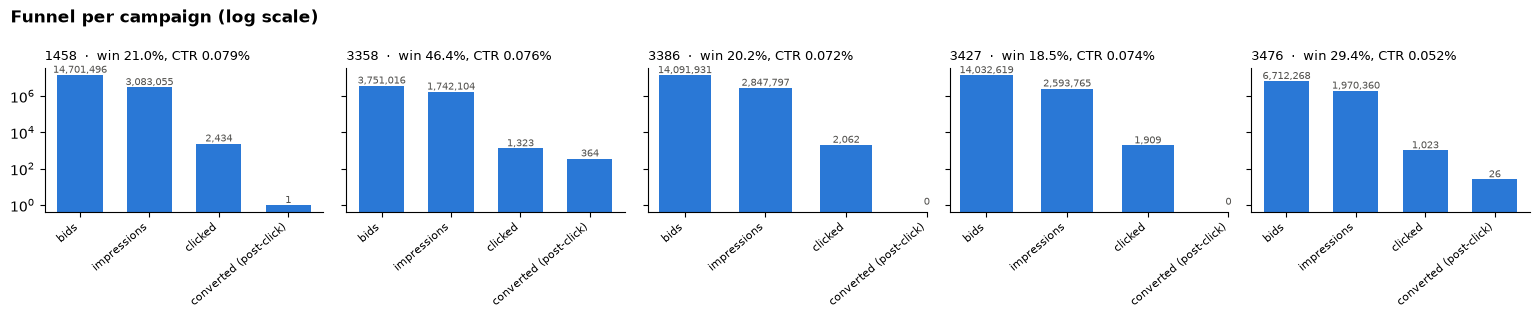

In [8]:
# CELL 8: funnel chart (bids -> impressions -> clicked -> converted), log scale, one panel per campaign
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print("pip install matplotlib to draw the chart")
if plt:
    stages = ["bids", "imps", "clicked_imps", "postclick_conv_imps"]
    labels = ["bids", "impressions", "clicked", "converted (post-click)"]
    rows = kpi[kpi.advertiser_id != "ALL"]
    fig, axes = plt.subplots(1, len(rows), figsize=(3.1 * len(rows), 3.2), sharey=True)
    for ax, (_, r) in zip(np.atleast_1d(axes), rows.iterrows()):
        vals = [r[s] if r[s] > 0 else np.nan for s in stages]   # no bar for 0 (log scale)
        ax.bar(range(4), vals, color="#2a78d6", width=0.65)
        ax.set_yscale("log")
        ax.set_xticks(range(4), labels, rotation=40, ha="right", fontsize=8)
        ax.set_title(f"{r.advertiser_id}  ·  win {r.win_rate:.1%}, CTR {r.ctr:.3%}", fontsize=9, loc="left")
        for x, s in enumerate(stages):
            ax.text(x, max(r[s], 0.8) * 1.3, f"{r[s]:,.0f}", ha="center", fontsize=7, color="#52514e")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    fig.suptitle("Funnel per campaign (log scale)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    out = PROJECT_ROOT / "reports" / "figures"
    try:
        out.mkdir(parents=True, exist_ok=True)
        fig.savefig(out / "02_funnel.png", dpi=150, bbox_inches="tight")   # a few KB
    except OSError:
        print("No disk space to save the PNG; the chart is shown here only.")
    plt.show()

In [9]:
# Story candidates for Notebook 10 (the data story): a few structured findings, saved as a small JSON file
import json
def save_story(notebook, candidates):
    """candidates: list of dicts with title, number, chart (PNG name in reports/figures), confidence, meaning."""
    out = PROJECT_ROOT / "reports" / "findings"
    try:
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{notebook}.json").write_text(json.dumps(
            [{**c, "notebook": notebook} for c in candidates], indent=2, default=str), encoding="utf-8")
        print(f"Saved {len(candidates)} story candidate(s) to reports/findings/{notebook}.json")
    except OSError:
        print("(no disk space: story candidates not saved)")

def conf_from_p(p):
    if p != p:
        return "Low (not tested)"
    return "High (p < 0.001)" if p < 0.001 else ("Medium (p = %.3f)" % p if p < 0.05 else "Low (p = %.2f, not significant)" % p)

## Findings

Generated from the numbers above.

In [10]:
# CELL 9: findings
tot = kpi[kpi.advertiser_id == "ALL"].iloc[0]
lk = link.pivot_table(index="tier", columns="log", values="share", fill_value=0)
t1_clk = link[(link.log == "clk") & link.tier.str.startswith("1")].share.sum()
orphan_clk = link[(link.log == "clk") & link.tier.str.startswith("4")].events.sum()
fails = checks[checks.violations > 0]
r_imp = recon[recon.metric == "impressions"].iloc[0]
r_bid = recon[recon.metric == "bids"].iloc[0]
r_cost = recon[recon.metric == "cost"].iloc[0]
r_clk = recon[recon.metric == "clicks"].assign(a=lambda d: d.diff_pct.abs()).sort_values("a").iloc[0]
r_cnv = recon[recon.metric == "conversions"].assign(a=lambda d: d.diff_pct.abs()).sort_values("a").iloc[0]
lc = lags.set_index("event")
best = kpi[kpi.advertiser_id != "ALL"].sort_values("ctr")
F = [
    f"**The funnel (5 campaigns, 6–12 June).** {tot.bids:,.0f} bids → {tot.imps:,.0f} impressions "
    f"(win rate {tot.win_rate:.1%}) → {tot.clicked_imps:,.0f} clicked impressions (CTR {tot.ctr:.3%}, 95% CI "
    f"{tot.ctr_lo:.3%}–{tot.ctr_hi:.3%}) → {tot.postclick_conv_imps:,.0f} post-click + {tot.postview_conv_imps:,.0f} "
    f"post-view converted impressions. Confidence: high (counts, not estimates).",
    f"**Linking needs more than bid_id.** {t1_clk:.1%} of clicks match on bid_id + user + an earlier impression. "
    f"Joining on bid_id alone would count {naive - proper:,} extra clicked impressions ({naive / proper - 1:+.1%}). "
    f"{orphan_clk:,} clicks have no impression and are excluded.",
    "**Nesting.** " + ("All checks pass." if fails.empty else
        "; ".join(f"{c}: {v:,}" for c, v in zip(fails.check, fails.violations)) + ". Investigate before trusting the KPIs."),
    f"**Reconciliation with the paper.** Bids {r_bid.diff_pct:+.2%}, impressions {r_imp.diff_pct:+.2%}, cost "
    f"{r_cost.diff_pct:+.2%}. Clicks match best as `{r_clk['our definition']}` ({r_clk.diff_pct:+.2%}) and "
    f"conversions as `{r_cnv['our definition']}` ({r_cnv.diff_pct:+.2%}).",
    f"**Conversion timing.** Median {lc.loc['conversion', 'median_min']:,.0f} min from impression to conversion "
    f"(p90 {lc.loc['conversion', 'p90_min']:,.0f} min); {lc.loc['conversion', 'share_on_later_day']:.0%} land on a "
    f"later day. Decision: report on the impression date.",
    f"**Campaigns differ.** CTR ranges from {best.iloc[0].ctr:.3%} ({best.iloc[0].advertiser_id}) to "
    f"{best.iloc[-1].ctr:.3%} ({best.iloc[-1].advertiser_id}). Only "
    + ", ".join(str(a) for a in kpi[(kpi.advertiser_id != 'ALL') & ((kpi.postclick_conv_imps + kpi.postview_conv_imps) > 0)].advertiser_id)
    + " record conversions, so CPA exists only for them.",
]
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(F, 1))))
per_1000 = 1000 * tot.ctr
cvr_all = tot.postclick_conv_imps / tot.clicked_imps if tot.clicked_imps else float("nan")
save_story("02_funnel_validation", [{
    "title": f"One impression in {1 / tot.ctr:,.0f} is clicked; one bid in {tot.bids / tot.imps:,.1f} wins",
    "number": f"{tot.bids:,.0f} bids → {tot.imps:,.0f} impressions (win rate {tot.win_rate:.1%}) → {tot.clicked_imps:,.0f} "
              f"clicked (CTR {tot.ctr:.3%}, 95% CI {tot.ctr_lo:.3%}–{tot.ctr_hi:.3%}) → {tot.postclick_conv_imps:,.0f} post-click "
              f"conversions; CPM {tot.cpm:.1f}, CPC {tot.cpc:.0f}",
    "chart": "02_funnel.png", "confidence": "High (exact counts, reconciled with the dataset paper)",
    "meaning": f"Expected value of 1,000 impressions = 1,000 × P(click) × P(conversion | click) × value per conversion "
               f"= {per_1000:.2f} clicks × {cvr_all:.1%} × value. To hit a target CPA T, CPM must stay below "
               f"{per_1000 * cvr_all:.3f} × T. This is the yardstick for every bid.",
}])

1. **The funnel (5 campaigns, 6–12 June).** 53,289,330 bids → 12,237,081 impressions (win rate 23.0%) → 8,751 clicked impressions (CTR 0.072%, 95% CI 0.070%–0.073%) → 391 post-click + 0 post-view converted impressions. Confidence: high (counts, not estimates).
2. **Linking needs more than bid_id.** 80.6% of clicks match on bid_id + user + an earlier impression. Joining on bid_id alone would count 90 extra clicked impressions (+1.0%). 104 clicks have no impression and are excluded.
3. **Nesting.** clicks before their impression (clock skew): 655; clicks without any impression: 104; conversions without any impression: 13. Investigate before trusting the KPIs.
4. **Reconciliation with the paper.** Bids +0.00%, impressions +0.00%, cost +0.00%. Clicks match best as `clicks_distinct_bid_id` (-0.03%) and conversions as `convs_converted_imps` (-1.26%).
5. **Conversion timing.** Median 1 min from impression to conversion (p90 19 min); 0% land on a later day. Decision: report on the impression date.
6. **Campaigns differ.** CTR ranges from 0.052% (3476) to 0.079% (1458). Only 1458, 3358, 3476 record conversions, so CPA exists only for them.

Saved 1 story candidate(s) to reports/findings/02_funnel_validation.json
